# Профиль рекомендаций: покрытие, разнообразие, длительность

**Цель:** ответить на вопрос «чем отличаются рекомендации 
и почему». В этом ноутбуке π_ref, R0 (β=2.0), R3 (λ=0.03, β=2.0) будут сравниваться по:
- **покрытие каталога@10** — какая доля каталога попадает в top-10;
- **Gini по показам** — концентрируются ли рекомендации на популярных айтемах;
- **доля top-1 айтема** — «всем одно и то же» или персонализация;
- **средняя популярность** (log) — не скатывается ли в популярное;
- **item_mean** — согласуется ли с судьёй;
- **длительность рекомендованных айтемов** — не уходит ли RL к короткому;
- **разнообразие жанров.**

### Импорты и пути

In [1]:
import sys
sys.path.append('../src')

import torch
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path
import importlib
from collections import Counter

from tqdm.auto import tqdm

import reward_functions as rf_mod
importlib.reload(rf_mod)
from reward_functions import build_item_mean_map

from dataset import build_item_vocab
from model import create_model
from reward_model import create_reward_model
from rm_index import RMIndex
from metrics import build_eval_targets, build_context

PROC = Path('../data/processed')
RESULTS = Path('../results')
RESULTS_PROFILE = RESULTS / 'profile_results'
RESULTS_PROFILE.mkdir(exist_ok=True)

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f"Device: {device}")

Device: cuda


### Данные и словарь

In [2]:
train_df = pd.read_parquet(PROC / 'train.parquet')
val_df   = pd.read_parquet(PROC / 'val.parquet')
test_df  = pd.read_parquet(PROC / 'test.parquet')

item2idx, idx2item = build_item_vocab(train_df)
vocab_size = len(item2idx) + 2
print(f"Vocab size: {vocab_size}")
print(f"Catalog size: {len(item2idx)}")

Vocab size: 14937
Catalog size: 14935


### item_en.csv

In [3]:
possible_paths = [
    PROC / 'items_en.csv',
    PROC.parent / 'raw' / 'items_en.csv',
    PROC.parent.parent / 'data' / 'raw' / 'items_en.csv',
]
items_path = next((p for p in possible_paths if p.exists()), None)

if items_path is not None:
    items_df = pd.read_csv(items_path)
    print(f"items_en.csv: {items_df.shape}, columns: {items_df.columns.tolist()[:10]}...")
    has_items = True
else:
    print("items_en.csv не найден — анализ жанров будет пропущен")
    has_items = False
    items_df = None

items_en.csv: (15963, 17), columns: ['Unnamed: 0', 'item_id', 'content_type', 'title', 'title_orig', 'release_year', 'genres', 'countries', 'for_kids', 'age_rating']...


### item_mean_map и popularity

In [4]:
all_df = pd.concat([train_df, val_df, test_df], ignore_index=True)
idx = RMIndex(all_df, item2idx, t1='2021-07-24', t2='2021-08-04')

item_mean_map = build_item_mean_map(idx, idx2item)
popularity_count = train_df.groupby('item_id').size().to_dict()
print(f"item_mean_map: {len(item_mean_map)} items, popularity: {len(popularity_count)}")

RMIndex: 4,632,197 событий
  train: 2,789,962
  val:   371,021
  test:  474,130
item_mean_map: 14434 items, popularity: 14935


### Длительность айтемов (из train_df)

In [5]:
# Оценка длительности айтема: median(total_dur / (watched_pct/100))
# для событий с watched_pct >= 50 (чтобы избежать шума от закрытых в начале)
train_valid = train_df[(train_df['watched_pct'] >= 50) & (train_df['watched_pct'] <= 100)].copy()
train_valid['watched_frac'] = train_valid['watched_pct'] / 100.0
train_valid['item_duration_est'] = train_valid['total_dur'] / train_valid['watched_frac']

item_duration = train_valid.groupby('item_id')['item_duration_est'].median().to_dict()
print(f"item_duration: {len(item_duration)} items")
print(f"Пример: item {list(item_duration.keys())[0]} -> ~{list(item_duration.values())[0]:.0f} сек")
print(f"Медиана по всем: {np.median(list(item_duration.values())):.0f} сек")

item_duration: 11971 items
Пример: item 0 -> ~22611 сек
Медиана по всем: 6515 сек


### Загрузка моделей

In [6]:
def load_gpt2_policy(ckpt):
    m = create_model(vocab_size=vocab_size)
    m.load_state_dict(torch.load(ckpt, map_location='cpu'))
    return m

ref_policy = load_gpt2_policy(RESULTS / 'checkpoints_v2' / 'best_model.pt').to(device).eval()
policy_r0 = load_gpt2_policy(RESULTS / 'checkpoints_rl_r0_beta2.0' / 'final_model.pt').to(device).eval()
policy_r3 = load_gpt2_policy(RESULTS / 'checkpoints_rl_r3_lam0.03_beta2.0' / 'final_model.pt').to(device).eval()

for p in [ref_policy, policy_r0, policy_r3]:
    for param in p.parameters():
        param.requires_grad = False

print("Loaded: π_ref, R0, R3")

[transformers] Model config: bos_token_id must be `None` or an integer within the vocabulary (between 0 and 14936), got 50256. This may result in unexpected behavior.
[transformers] Model config: eos_token_id must be `None` or an integer within the vocabulary (between 0 and 14936), got 50256. This may result in unexpected behavior.


Loaded: π_ref, R0, R3


### Контексты для профиля

In [7]:
test_targets = build_eval_targets(test_df)
test_context = build_context(train_df, val_df)

test_users = test_targets['user_id'].unique()
np.random.seed(123)
eval_users = np.random.choice(test_users, size=2000, replace=False).tolist()

eval_contexts = []
for u in eval_users:
    ctx = test_context.get(u)
    items = ctx['items'] if ctx else []
    eval_contexts.append(list(items)[-50:])

print(f"Eval: {len(eval_users)} users")
assert all(len(c) > 0 for c in eval_contexts)

Eval: 2000 users


### Функция профиля

In [8]:
@torch.no_grad()
def profile_metrics(policy, contexts, K=10, max_len=50, device='cuda'):
    """
    Считает метрики профиля рекомендаций для политики на контекстах.
    """
    B = len(contexts)
    inp = torch.zeros(B, max_len, dtype=torch.long, device=device)
    for i, ctx in enumerate(contexts):
        recent = ctx[-max_len:]
        indexed = [item2idx.get(int(x), 1) for x in recent]
        if indexed:
            inp[i, -len(indexed):] = torch.tensor(indexed, device=device)

    logits = policy(inp).logits[:, -1, :].clone()
    logits[:, 0] = -1e9
    logits[:, 1] = -1e9
    for i, ctx in enumerate(contexts):
        seen = [item2idx[int(x)] for x in ctx if int(x) in item2idx]
        if seen:
            logits[i, torch.tensor(seen, device=device)] = -1e9

    topK = torch.topk(logits, K, dim=-1).indices.cpu().tolist()

    all_items = []
    item_counts = Counter()
    user_durations = []
    user_genres = []  # list of lists of genre-sets per user
    repeat_count = 0

    for i, row in enumerate(topK):
        user_items = [idx2item[int(j)] for j in row]
        all_items.extend(user_items)
        item_counts.update(user_items)
        if len(user_items) != len(set(user_items)):
            repeat_count += 1

        # длительность
        durs = [item_duration.get(it, np.nan) for it in user_items]
        durs = [d for d in durs if not np.isnan(d)]
        if durs:
            user_durations.append(np.median(durs))

    n_unique = len(item_counts)
    catalog_size = len(item2idx)
    coverage_pct = 100.0 * n_unique / catalog_size

    # Gini по показам
    counts = np.array(sorted(item_counts.values()))
    n = len(counts)
    if n > 1 and counts.sum() > 0:
        idx_arr = np.arange(1, n + 1)
        gini = (2 * np.sum(idx_arr * counts) / (n * counts.sum())) - (n + 1) / n
    else:
        gini = 0.0

    most_common = item_counts.most_common(1)[0]
    top1_item, top1_count = most_common

    avg_pop = np.mean([popularity_count.get(it, 0) for it in all_items])
    log_avg_pop = np.log1p(avg_pop)

    avg_im = np.mean([item_mean_map.get(it, 0.5) for it in all_items])
    med_dur = np.median(user_durations) if user_durations else float('nan')

    return {
        'coverage_pct': coverage_pct,
        'n_unique': n_unique,
        'gini': gini,
        'top10_dominance_item': int(top1_item),
        'top10_dominance': top1_count / B,
        'avg_pop': avg_pop,
        'log_avg_pop': log_avg_pop,
        'avg_item_mean': avg_im,
        'median_duration': med_dur,
        'repeat_users': repeat_count / B,
        'all_items': all_items,
    }

### Запуск для трёх моделей

In [9]:
print("[profile] π_ref ...")
prof_ref = profile_metrics(ref_policy, eval_contexts, K=10, device=device)
print("[profile] R0 (β=2.0) ...")
prof_r0 = profile_metrics(policy_r0, eval_contexts, K=10, device=device)
print("[profile] R3 (λ=0.03, β=2.0) ...")
prof_r3 = profile_metrics(policy_r3, eval_contexts, K=10, device=device)

print("\nПрофиль посчитан")

[profile] π_ref ...
[profile] R0 (β=2.0) ...
[profile] R3 (λ=0.03, β=2.0) ...

Профиль посчитан


### Сравнительная таблица

In [10]:
def summarize(name, prof):
    return {
        'model': name,
        'coverage_%': prof['coverage_pct'],
        'unique_items': prof['n_unique'],
        'gini': prof['gini'],
        'top10_dominance_item': prof['top10_dominance_item'],
        'top10_dominance_%': prof['top10_dominance'] * 100,
        'avg_popularity': prof['avg_pop'],
        'log_avg_pop': prof['log_avg_pop'],
        'avg_item_mean': prof['avg_item_mean'],
        'median_duration_s': prof['median_duration'],
        'repeat_users_%': prof['repeat_users'] * 100,
    }

summary = pd.DataFrame([
    summarize('π_ref', prof_ref),
    summarize('R0 (β=2.0)', prof_r0),
    summarize('R3 (λ=0.03, β=2.0)', prof_r3),
])

print(f"\n{'='*110}")
print("ПРОФИЛЬ РЕКОМЕНДАЦИЙ (2000 test-контекстов, top-10)")
print(f"{'='*110}")
print(summary.to_string(index=False, float_format=lambda x: f"{x:.2f}"))
print(f"{'='*110}")

summary.to_csv(RESULTS_PROFILE / 'profile_comparison.csv', index=False)
print(f"\nСохранено: {RESULTS_PROFILE / 'profile_comparison.csv'}")


ПРОФИЛЬ РЕКОМЕНДАЦИЙ (2000 test-контекстов, top-10)
             model  coverage_%  unique_items  gini  top10_dominance_item  top10_dominance_%  avg_popularity  log_avg_pop  avg_item_mean  median_duration_s  repeat_users_%
             π_ref        6.14           917  0.87                  9728              67.65        44039.26        10.69           0.52            7871.12            0.00
        R0 (β=2.0)        6.18           923  0.87                  9728              69.60        43514.64        10.68           0.56            7676.00            0.00
R3 (λ=0.03, β=2.0)        6.04           902  0.87                  9728              69.90        44027.43        10.69           0.55            7676.00            0.00

Сохранено: ..\results\profile_results\profile_comparison.csv


### Диагностика позиции 9728

In [11]:
pop_rank = sorted(popularity_count.items(), key=lambda x: -x[1])
pop_rank_dict = {item: rank+1 for rank, (item, _) in enumerate(pop_rank)}

for item in [9728]:
    print(f"Item {item}:")
    print(f"  rank in popularity: {pop_rank_dict.get(item, 'N/A')}")
    print(f"  popularity count: {popularity_count.get(item, 0)}")
    print(f"  item_mean (avg watched_pct): {item_mean_map.get(item, 'N/A'):.4f}")
    print(f"  duration (est): {item_duration.get(item, 'N/A'):.0f} sec")

Item 9728:
  rank in popularity: 4
  popularity count: 78750
  item_mean (avg watched_pct): 0.6882
  duration (est): 7676 sec


### Диагностика: топ-10 самых частых top-1 рекомендаций

In [12]:
# Для каждой модели — топ-10 самых частых top-1
from collections import Counter

@torch.no_grad()
def top1_distribution(policy, contexts, max_len=50, device='cuda'):
    B = len(contexts)
    inp = torch.zeros(B, max_len, dtype=torch.long, device=device)
    for i, ctx in enumerate(contexts):
        recent = ctx[-max_len:]
        indexed = [item2idx.get(int(x), 1) for x in recent]
        if indexed:
            inp[i, -len(indexed):] = torch.tensor(indexed, device=device)
    logits = policy(inp).logits[:, -1, :].clone()
    logits[:, 0] = -1e9
    logits[:, 1] = -1e9
    for i, ctx in enumerate(contexts):
        seen = [item2idx[int(x)] for x in ctx if int(x) in item2idx]
        if seen:
            logits[i, torch.tensor(seen, device=device)] = -1e9
    top1 = logits.argmax(-1).cpu().tolist()
    return Counter([idx2item[int(i)] for i in top1])

print("ТОП-10 САМЫХ ЧАСТЫХ TOP-1 РЕКОМЕНДАЦИЙ")
for name, policy in [('π_ref', ref_policy), ('R0', policy_r0), ('R3', policy_r3)]:
    dist = top1_distribution(policy, eval_contexts)
    print(f"\n{name}:")
    for item, count in dist.most_common(10):
        pct = 100 * count / len(eval_contexts)
        print(f"  item {item}: {count} users ({pct:.1f}%), pop_rank={pop_rank_dict.get(item, '?')}, "
              f"item_mean={item_mean_map.get(item, 0):.3f}")

ТОП-10 САМЫХ ЧАСТЫХ TOP-1 РЕКОМЕНДАЦИЙ

π_ref:
  item 10440: 445 users (22.2%), pop_rank=1, item_mean=0.572
  item 15297: 354 users (17.7%), pop_rank=2, item_mean=0.650
  item 9728: 253 users (12.7%), pop_rank=4, item_mean=0.688
  item 13865: 251 users (12.6%), pop_rank=3, item_mean=0.724
  item 4151: 119 users (6.0%), pop_rank=5, item_mean=0.457
  item 12192: 76 users (3.8%), pop_rank=22, item_mean=0.064
  item 3734: 70 users (3.5%), pop_rank=7, item_mean=0.790
  item 7829: 48 users (2.4%), pop_rank=61, item_mean=0.495
  item 4495: 30 users (1.5%), pop_rank=25, item_mean=0.610
  item 16228: 18 users (0.9%), pop_rank=49, item_mean=0.148

R0:
  item 13865: 409 users (20.4%), pop_rank=3, item_mean=0.724
  item 15297: 375 users (18.8%), pop_rank=2, item_mean=0.650
  item 10440: 349 users (17.4%), pop_rank=1, item_mean=0.572
  item 9728: 326 users (16.3%), pop_rank=4, item_mean=0.688
  item 3734: 117 users (5.8%), pop_rank=7, item_mean=0.790
  item 4151: 51 users (2.5%), pop_rank=5, item_m

### Диагностика: кол-во уникальных top-1 рекомендаций

In [13]:
for name, policy in [('π_ref', ref_policy), ('R0', policy_r0), ('R3', policy_r3)]:
    dist = top1_distribution(policy, eval_contexts)
    print(f"{name}: {len(dist)} unique top-1 items across {len(eval_contexts)} users")

π_ref: 169 unique top-1 items across 2000 users
R0: 159 unique top-1 items across 2000 users
R3: 149 unique top-1 items across 2000 users


### Разнообразие жанров

In [14]:
if has_items and 'genres' in items_df.columns:
    print("\nАнализ жанрового разнообразия...")
    # Очистка: разделитель может быть запятой, точкой с запятой, слэшем
    def parse_genres(s):
        if pd.isna(s):
            return set()
        s = str(s).replace(';', ',').replace('|', ',').replace('/', ',')
        return set(g.strip().lower() for g in s.split(',') if g.strip())

    item2genres = dict(zip(items_df['item_id'], items_df['genres'].map(parse_genres)))
    print(f"item2genres: {len(item2genres)} items")

    def genre_metrics(all_items):
        # Разнообразие жанров в top-10 одного пользователя
        # Все жанры, встреченные в top-10
        user_genre_div = []
        for i in range(len(eval_contexts)):
            user_top10 = all_items[i*10:(i+1)*10]
            genres_union = set()
            for it in user_top10:
                genres_union |= item2genres.get(it, set())
            user_genre_div.append(len(genres_union))
        return {
            'avg_genres_per_user_top10': np.mean(user_genre_div),
            'std_genres_per_user_top10': np.std(user_genre_div),
        }

    g_ref = genre_metrics(prof_ref['all_items'])
    g_r0 = genre_metrics(prof_r0['all_items'])
    g_r3 = genre_metrics(prof_r3['all_items'])

    print(f"\n{'='*70}")
    print("ЖАНРОВОЕ РАЗНООБРАЗИЕ В TOP-10")
    print(f"{'='*70}")
    print(f"{'Модель':<20} {'Ср. жанров':>12} {'Std':>10}")
    print("-" * 45)
    print(f"{'π_ref':<20} {g_ref['avg_genres_per_user_top10']:>12.2f} {g_ref['std_genres_per_user_top10']:>10.2f}")
    print(f"{'R0 (β=2.0)':<20} {g_r0['avg_genres_per_user_top10']:>12.2f} {g_r0['std_genres_per_user_top10']:>10.2f}")
    print(f"{'R3 (λ=0.03)':<20} {g_r3['avg_genres_per_user_top10']:>12.2f} {g_r3['std_genres_per_user_top10']:>10.2f}")
    print("-" * 45)
else:
    print("\nАнализ жанров пропущен: items_en.csv или колонка 'genres' не найдены")


Анализ жанрового разнообразия...
item2genres: 15963 items

ЖАНРОВОЕ РАЗНООБРАЗИЕ В TOP-10
Модель                 Ср. жанров        Std
---------------------------------------------
π_ref                       10.48       2.08
R0 (β=2.0)                  10.67       2.18
R3 (λ=0.03)                 10.65       2.15
---------------------------------------------


### Визуализация

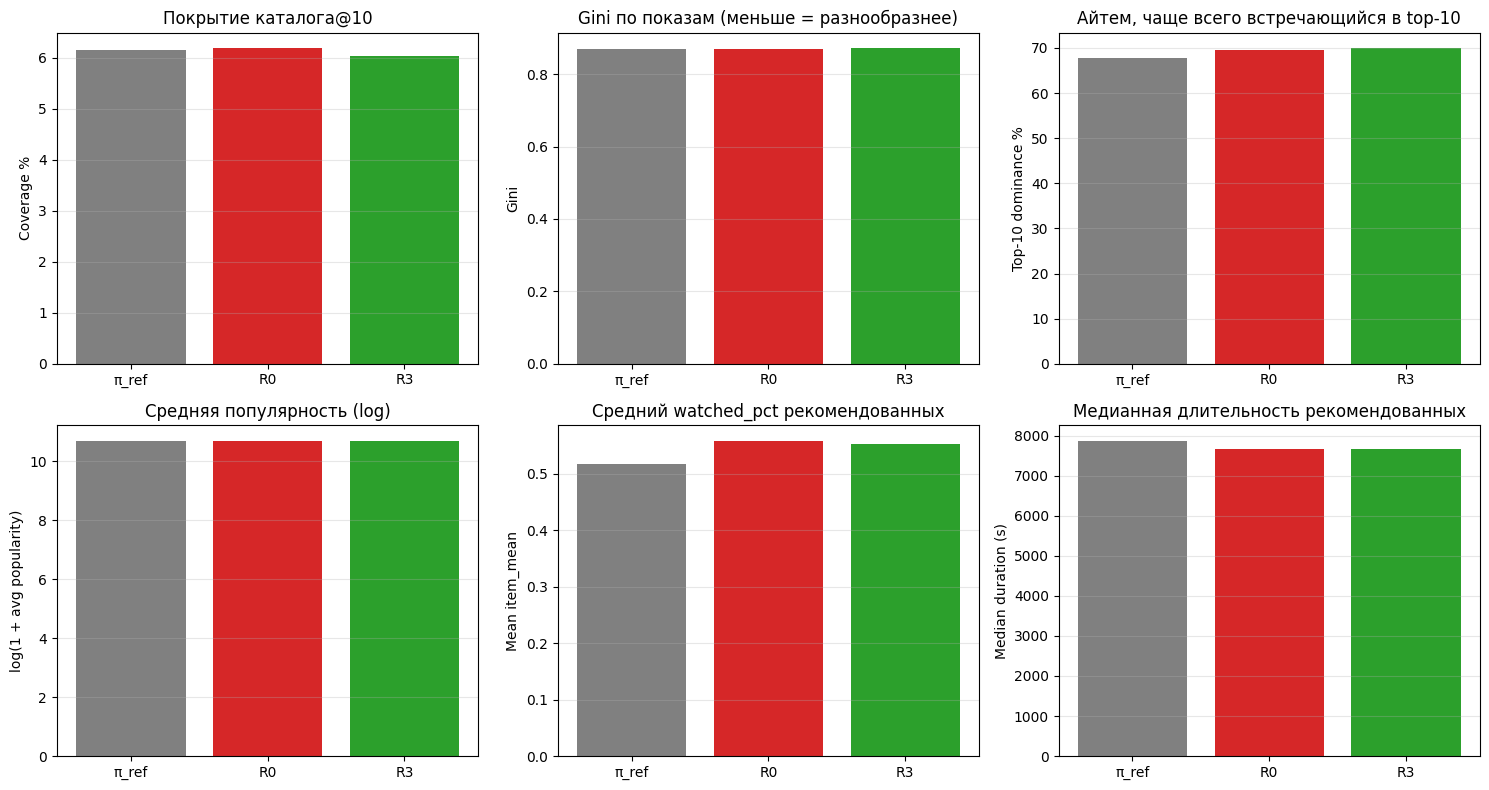

Сохранено: ..\results\profile_results\profile_comparison.png


In [17]:
fig, axes = plt.subplots(2, 3, figsize=(15, 8))

models = ['π_ref', 'R0', 'R3']
colors = ['gray', '#d62728', '#2ca02c']

# 1. Coverage
ax = axes[0, 0]
vals = [prof_ref['coverage_pct'], prof_r0['coverage_pct'], prof_r3['coverage_pct']]
ax.bar(models, vals, color=colors)
ax.set_ylabel('Coverage %')
ax.set_title('Покрытие каталога@10')
ax.grid(alpha=0.3, axis='y')

# 2. Gini
ax = axes[0, 1]
vals = [prof_ref['gini'], prof_r0['gini'], prof_r3['gini']]
ax.bar(models, vals, color=colors)
ax.set_ylabel('Gini')
ax.set_title('Gini по показам (меньше = разнообразнее)')
ax.grid(alpha=0.3, axis='y')

# 3. Top-1 share
ax = axes[0, 2]
vals = [prof_ref['top10_dominance']*100,
        prof_r0['top10_dominance']*100,
        prof_r3['top10_dominance']*100]
ax.bar(models, vals, color=colors)
ax.set_ylabel('Top-10 dominance %')
ax.set_title('Айтем, чаще всего встречающийся в top-10')
ax.grid(alpha=0.3, axis='y')

# 4. Avg popularity (log)
ax = axes[1, 0]
vals = [prof_ref['log_avg_pop'], prof_r0['log_avg_pop'], prof_r3['log_avg_pop']]
ax.bar(models, vals, color=colors)
ax.set_ylabel('log(1 + avg popularity)')
ax.set_title('Средняя популярность (log)')
ax.grid(alpha=0.3, axis='y')

# 5. Avg item_mean
ax = axes[1, 1]
vals = [prof_ref['avg_item_mean'], prof_r0['avg_item_mean'], prof_r3['avg_item_mean']]
ax.bar(models, vals, color=colors)
ax.set_ylabel('Mean item_mean')
ax.set_title('Средний watched_pct рекомендованных')
ax.grid(alpha=0.3, axis='y')

# 6. Median duration
ax = axes[1, 2]
vals = [prof_ref['median_duration'], prof_r0['median_duration'], prof_r3['median_duration']]
ax.bar(models, vals, color=colors)
ax.set_ylabel('Median duration (s)')
ax.set_title('Медианная длительность рекомендованных')
ax.grid(alpha=0.3, axis='y')

plt.tight_layout()
out_path = RESULTS_PROFILE / 'profile_comparison.png'
plt.savefig(out_path, dpi=130, bbox_inches='tight')
plt.show()
print(f"Сохранено: {out_path}")

### Сохранение

In [18]:
import pickle
with open(RESULTS_PROFILE / 'profile_full.pkl', 'wb') as f:
    pickle.dump({
        'eval_users': eval_users,
        'eval_contexts': eval_contexts,
        'prof_ref': {k: v for k, v in prof_ref.items() if k != 'all_items'},
        'prof_r0':  {k: v for k, v in prof_r0.items()  if k != 'all_items'},
        'prof_r3':  {k: v for k, v in prof_r3.items()  if k != 'all_items'},
    }, f)
print(f"Сохранено: {RESULTS_PROFILE / 'profile_full.pkl'}")

Сохранено: ..\results\profile_results\profile_full.pkl
